正在计算：(0,4), CPS (Table I)
  F(g_opt) = 0.996527; paper = 0.997
正在计算：(1,1), OCS (Table II)
  F(g_opt) = 0.992161; paper = 0.992
正在计算：(2,2), OCS (Table II)
  F(g_opt) = 0.999331; paper = 0.999
正在计算：(2,2), ECS (Table III)
  F(g_opt) = 0.999081; paper = 0.999
正在计算：(1,2), ECS (Table IV)
  F(g_opt) = 0.993612; paper = 0.991
正在计算：(3,2), ECS (Table IV)
  F(g_opt) = 0.995720; paper = 0.996

OPA gain and input-alpha tolerance table
Configuration               Input          g_opt    F(g_opt)         g tol, F>=0.99         g tol, F>=0.95       alpha tol, F>=0.99
------------------------------------------------------------------------------------------------------------------------------------------------------
(0,4), CPS (Table I)        Coherent        1.46    0.996527         [-4.4%, +5.1%]       [-11.5%, +14.6%]           [-4.8%, +4.6%]
(1,1), OCS (Table II)       Odd cat         1.60    0.992161         [-0.6%, +2.8%]         [-4.2%, +9.5%]           [-7.3%, +2.7%]
(2,2), OCS (Table II)      

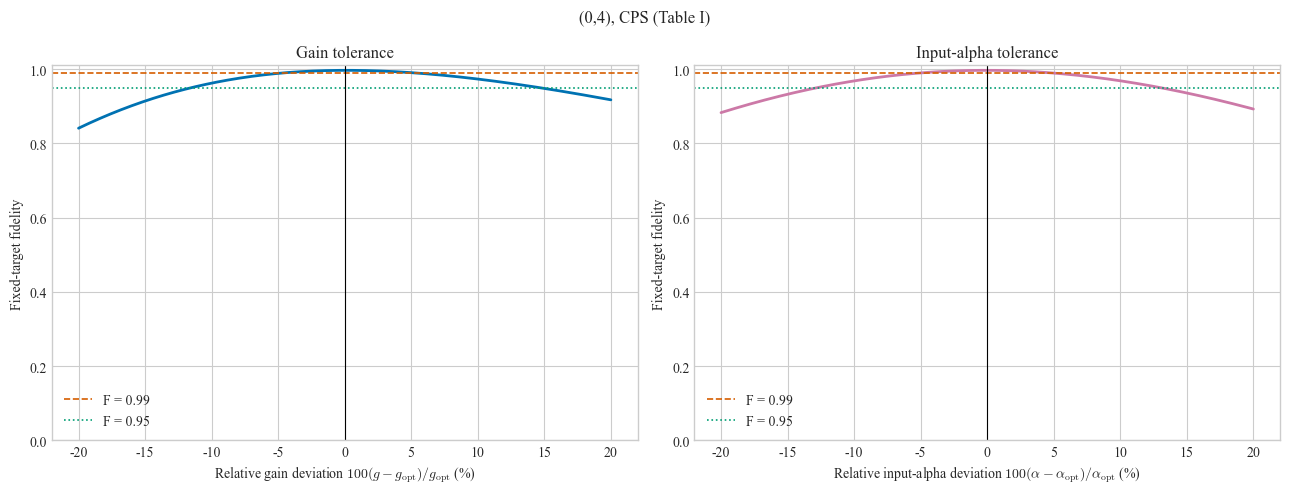

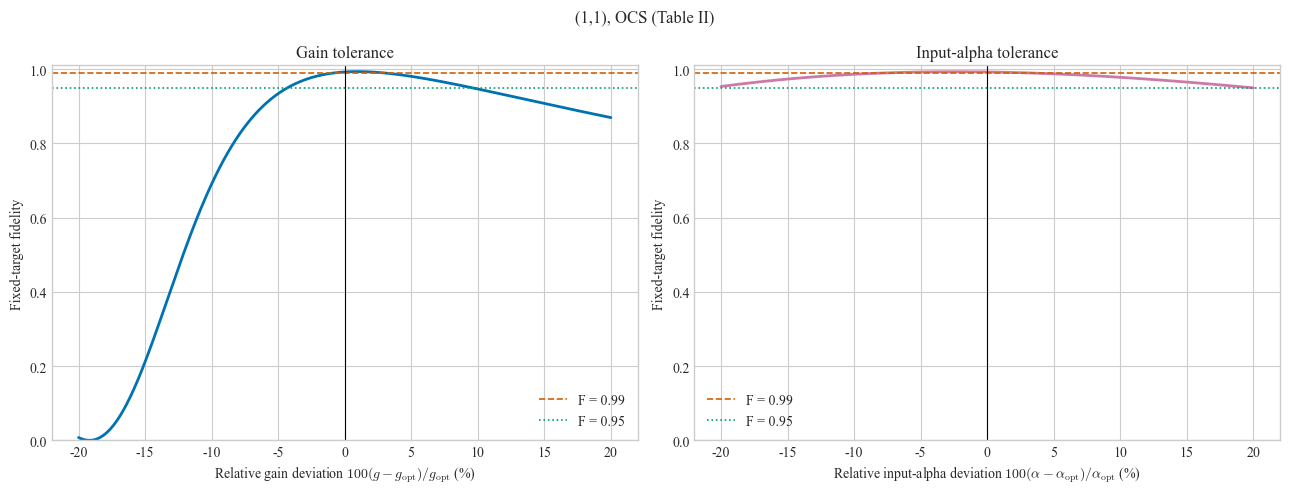

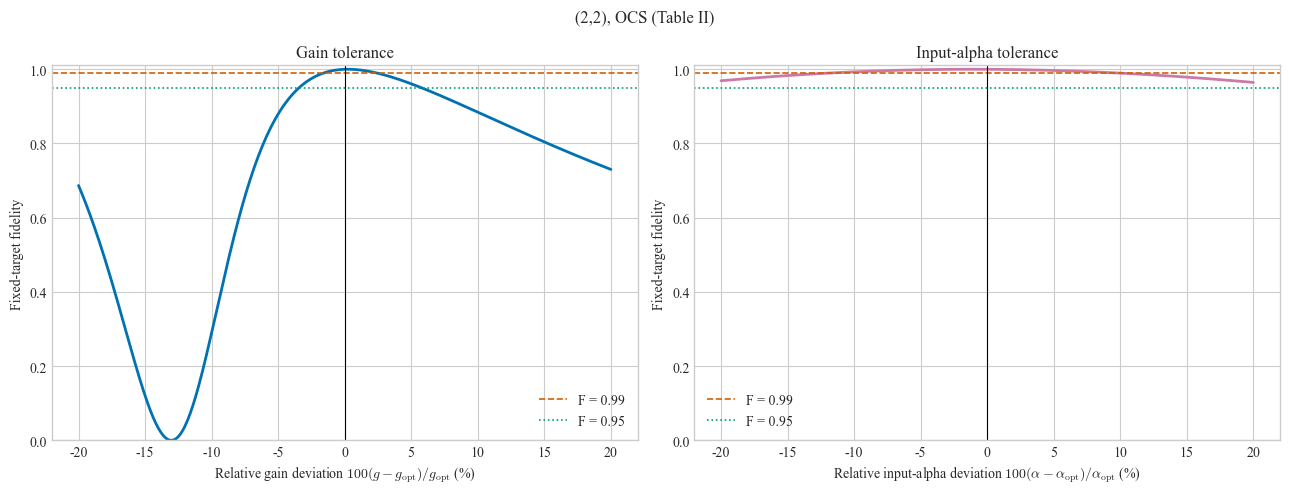

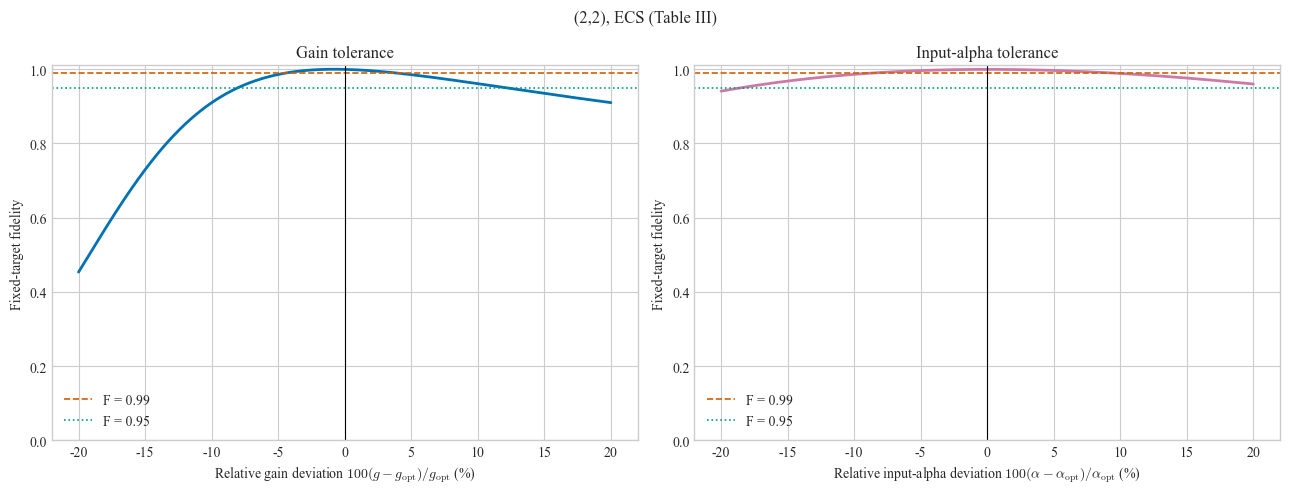

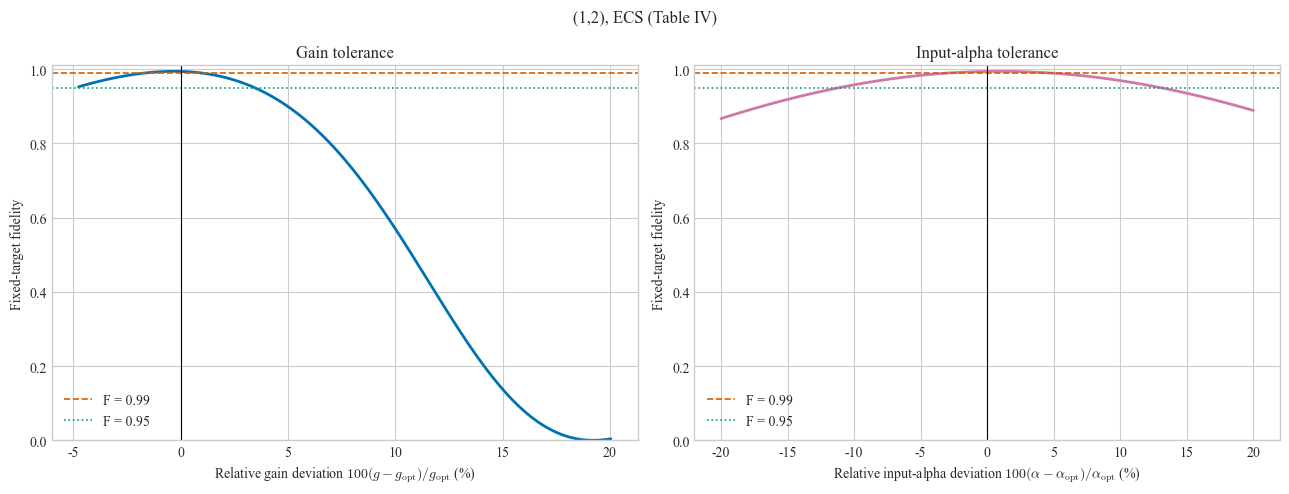

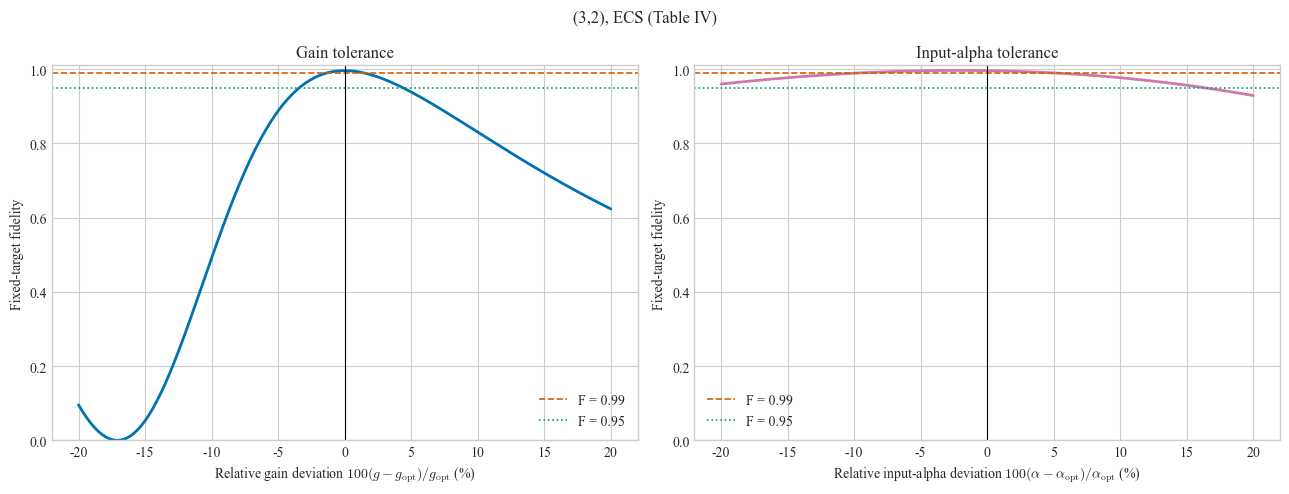

In [2]:
# ============================================================
# OPA 参数容差分析
# 同时分析 g 容差和输入 alpha 容差
# ============================================================

from __future__ import annotations

import csv
import math
from pathlib import Path

import numpy as np
import qutip as qt
import matplotlib.pyplot as plt


# ============================================================
# 1. 全局计算参数
# ============================================================

N_DIM = 60

# g 的相对扫描范围和步长
RELATIVE_HALF_WIDTH = 0.20     # 扫描 g_opt 的 +/-20%
RELATIVE_STEP = 0.001          # 每个点间隔 0.1%

# alpha 的相对扫描范围和步长
ALPHA_HALF_WIDTH = 0.20        # 扫描 alpha_opt 的 +/-20%
ALPHA_STEP = 0.001             # 每个点间隔 0.1%

# g 必须严格大于 1
MIN_GAIN = 1.0001

# 保真度阈值
THRESHOLDS = (0.99, 0.95)

# 输出目录
OUT_DIR = Path("OPA_gain_alpha_tolerance_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 是否绘制曲线
MAKE_PLOTS = True


# ============================================================
# 2. 第二篇论文中的代表性参数
# ============================================================

CASES = [
    {
        "label": "(0,4), CPS (Table I)",
        "family": "cps",
        "input_state": "Coherent",

        "m": 0,
        "n": 4,
        "g_opt": 1.46,

        # Table I 参数
        "gamma_prime": 0.103,
        "target_r": 0.0,
        "alpha": -2.145j,
        "r_corr": 0.521,
        "beta_corr": 2.963j,

        "paper_fidelity": 0.997,
    },

    {
        "label": "(1,1), OCS (Table II)",
        "family": "cat",
        "input_state": "Odd cat",

        "m": 1,
        "n": 1,
        "g_opt": 1.60,

        "alpha_in": 1.06,
        "alpha_out": 2.02,
        "target_gamma": 0.34,

        "input_parity": "odd",
        "target_parity": "odd",

        "paper_fidelity": 0.992,
    },

    {
        "label": "(2,2), OCS (Table II)",
        "family": "cat",
        "input_state": "Odd cat",

        "m": 2,
        "n": 2,
        "g_opt": 1.36,

        "alpha_in": 1.06,
        "alpha_out": 1.67,
        "target_gamma": 0.31,

        "input_parity": "odd",
        "target_parity": "odd",

        "paper_fidelity": 0.999,
    },

    {
        "label": "(2,2), ECS (Table III)",
        "family": "cat",
        "input_state": "Even cat",

        "m": 2,
        "n": 2,
        "g_opt": 2.80,

        "alpha_in": 1.00,
        "alpha_out": 1.71,
        "target_gamma": 0.246,

        "input_parity": "even",
        "target_parity": "even",

        "paper_fidelity": 0.999,
    },

    {
        "label": "(1,2), ECS (Table IV)",
        "family": "cat",
        "input_state": "Even cat",

        "m": 1,
        "n": 2,
        "g_opt": 1.05,

        "alpha_in": 1.97,
        "alpha_out": 2.69,
        "target_gamma": 0.20,

        "input_parity": "even",
        "target_parity": "odd",

        "paper_fidelity": 0.991,
    },

    {
        "label": "(3,2), ECS (Table IV)",
        "family": "cat",
        "input_state": "Even cat",

        "m": 3,
        "n": 2,
        "g_opt": 1.60,

        "alpha_in": 1.45,
        "alpha_out": 2.00,
        "target_gamma": 0.49,

        "input_parity": "even",
        "target_parity": "odd",

        "paper_fidelity": 0.996,
    },
]


# ============================================================
# 3. OPA 条件态
# ============================================================

def attenuate_fock_amplitudes(state: qt.Qobj, gain: float) -> qt.Qobj:
    """
    实现 g^(-a^dagger a)。
    """
    amplitudes = state.full().ravel()
    factors = gain ** (-np.arange(len(amplitudes)))

    return qt.Qobj(
        (amplitudes * factors).reshape((-1, 1)),
        dims=state.dims,
    )


def h_coefficient(
    k: int,
    m: int,
    n: int,
    gain: float,
) -> float:
    """
    第二篇论文式 (4) 中的 H(k,m,n)。
    """
    added = n - m + k

    if added < 0:
        return 0.0

    G = math.sqrt(1.0 - 1.0 / gain**2)

    numerator = (
        (-1) ** added
        * G ** (n - m + 2 * k)
        * math.sqrt(math.factorial(n) * math.factorial(m))
    )

    denominator = (
        gain ** (m - k + 1)
        * math.factorial(k)
        * math.factorial(added)
        * math.factorial(m - k)
    )

    return numerator / denominator


def opa_heralded_state(
    signal: qt.Qobj,
    m: int,
    n: int,
    gain: float,
) -> qt.Qobj:
    """
    第二篇论文式 (3) 的未归一化条件输出态。
    """
    if gain <= 1.0:
        raise ValueError("OPA gain must satisfy g > 1.")

    dim = signal.shape[0]
    a = qt.destroy(dim)

    output = 0.0 * signal

    for k in range(m + 1):
        coefficient = h_coefficient(k, m, n, gain)

        if coefficient == 0.0:
            continue

        added = n - m + k

        output += (
            coefficient
            * (a.dag() ** added)
            * attenuate_fock_amplitudes((a ** k) * signal, gain)
        )

    return output


# ============================================================
# 4. 输入态和目标态
# ============================================================

def cat_state(
    dim: int,
    alpha: float,
    parity: str,
) -> qt.Qobj:
    """
    构造归一化奇猫态或偶猫态。
    """
    if parity == "odd":
        sign = -1.0
    elif parity == "even":
        sign = 1.0
    else:
        raise ValueError("parity must be 'odd' or 'even'.")

    state = (
        qt.coherent(dim, alpha)
        + sign * qt.coherent(dim, -alpha)
    )

    return state.unit()


def cps_target_state(
    dim: int,
    gamma_prime: float,
    target_r: float,
) -> qt.Qobj:
    """
    CPS 目标态。

    注意：
    为了复现原 Table I 代码，采用
        x = a + a.dag()
    而不是
        x = (a + a.dag()) / sqrt(2)
    """
    a = qt.destroy(dim)
    x = a + a.dag()

    vacuum = qt.basis(dim, 0)
    squeeze_state = qt.squeeze(dim, target_r) * vacuum
    cubic_operator = (1j * gamma_prime * (x ** 3)).expm()

    return (cubic_operator * squeeze_state).unit()


def build_target_state(case: dict) -> qt.Qobj:
    """
    根据不同输入态构造固定目标态。
    """
    dim = N_DIM

    if case["family"] == "cps":
        return cps_target_state(
            dim=dim,
            gamma_prime=case["gamma_prime"],
            target_r=case["target_r"],
        )

    if case["family"] == "cat":
        target_cat = cat_state(
            dim=dim,
            alpha=case["alpha_out"],
            parity=case["target_parity"],
        )

        return (
            qt.squeeze(dim, case["target_gamma"])
            * target_cat
        ).unit()

    raise ValueError(f"Unknown family: {case['family']}")


# ============================================================
# 5. 保真度函数
# ============================================================

def fidelity_for_gain(
    case: dict,
    gain: float,
    target: qt.Qobj,
) -> float:
    """
    固定输入 alpha，只改变 g。
    """
    dim = N_DIM

    if case["family"] == "cps":
        signal = qt.coherent(dim, case["alpha"])

        raw_output = opa_heralded_state(
            signal=signal,
            m=case["m"],
            n=case["n"],
            gain=gain,
        )

        # 论文公式对应的顺序：
        # S(r_corr) D(beta_corr) |Psi>
        corrected_output = (
            qt.squeeze(dim, case["r_corr"])
            * qt.displace(dim, case["beta_corr"])
            * raw_output
        )

    elif case["family"] == "cat":
        signal = cat_state(
            dim=dim,
            alpha=case["alpha_in"],
            parity=case["input_parity"],
        )

        corrected_output = opa_heralded_state(
            signal=signal,
            m=case["m"],
            n=case["n"],
            gain=gain,
        )

    else:
        raise ValueError(f"Unknown family: {case['family']}")

    if corrected_output.norm() < 1e-14:
        return float("nan")

    return float(
        abs(target.overlap(corrected_output.unit())) ** 2
    )


def fidelity_for_alpha(
    case: dict,
    alpha: complex | float,
    target: qt.Qobj,
) -> float:
    """
    固定 g=g_opt，只改变输入 alpha。
    """
    dim = N_DIM
    gain = case["g_opt"]

    if case["family"] == "cps":
        signal = qt.coherent(dim, alpha)

        raw_output = opa_heralded_state(
            signal=signal,
            m=case["m"],
            n=case["n"],
            gain=gain,
        )

        corrected_output = (
            qt.squeeze(dim, case["r_corr"])
            * qt.displace(dim, case["beta_corr"])
            * raw_output
        )

    elif case["family"] == "cat":
        signal = cat_state(
            dim=dim,
            alpha=float(alpha),
            parity=case["input_parity"],
        )

        corrected_output = opa_heralded_state(
            signal=signal,
            m=case["m"],
            n=case["n"],
            gain=gain,
        )

    else:
        raise ValueError(f"Unknown family: {case['family']}")

    if corrected_output.norm() < 1e-14:
        return float("nan")

    return float(
        abs(target.overlap(corrected_output.unit())) ** 2
    )


# ============================================================
# 6. 提取中心连通容差区间
# ============================================================

def central_interval(
    relative_values: np.ndarray,
    fidelities: np.ndarray,
    threshold: float,
):
    """
    只提取包含零偏差点的连续区间。

    返回：
        lower,
        upper,
        lower_boundary_limited,
        upper_boundary_limited
    """
    center = int(np.argmin(np.abs(relative_values)))

    valid = (
        np.isfinite(fidelities)
        & (fidelities >= threshold)
    )

    if not valid[center]:
        return None

    left = center
    right = center

    while left > 0 and valid[left - 1]:
        left -= 1

    while right < len(relative_values) - 1 and valid[right + 1]:
        right += 1

    return (
        float(relative_values[left]),
        float(relative_values[right]),
        left == 0,
        right == len(relative_values) - 1,
    )


# ============================================================
# 7. 运行 g 和 alpha 扫描
# ============================================================

def run_tolerance_analysis():
    all_g_scan_rows = []
    all_alpha_scan_rows = []
    table_rows = []

    for case in CASES:
        print(f"正在计算：{case['label']}")

        target = build_target_state(case)

        g_opt = case["g_opt"]

        # ----------------------------------------------------
        # 7.1 g 扫描
        # ----------------------------------------------------

        g_delta_min = max(
            -RELATIVE_HALF_WIDTH,
            MIN_GAIN / g_opt - 1.0,
        )

        g_delta_values = np.arange(
            g_delta_min,
            RELATIVE_HALF_WIDTH + 0.5 * RELATIVE_STEP,
            RELATIVE_STEP,
        )

        g_values = g_opt * (1.0 + g_delta_values)

        g_fidelities = np.array([
            fidelity_for_gain(case, gain, target)
            for gain in g_values
        ])

        baseline_fidelity = fidelity_for_gain(
            case,
            g_opt,
            target,
        )

        # ----------------------------------------------------
        # 7.2 alpha 扫描
        # ----------------------------------------------------

        if case["family"] == "cps":
            alpha_opt = case["alpha"]
        else:
            alpha_opt = case["alpha_in"]

        alpha_delta_values = np.arange(
            -ALPHA_HALF_WIDTH,
            ALPHA_HALF_WIDTH + 0.5 * ALPHA_STEP,
            ALPHA_STEP,
        )

        alpha_values = alpha_opt * (1.0 + alpha_delta_values)

        alpha_fidelities = np.array([
            fidelity_for_alpha(case, alpha, target)
            for alpha in alpha_values
        ])

        # ----------------------------------------------------
        # 7.3 构造表格行
        # ----------------------------------------------------

        row = {
            "configuration": case["label"],
            "input_state": case["input_state"],
            "g_opt": g_opt,
            "F_g_opt": baseline_fidelity,
            "paper_F": case["paper_fidelity"],
        }

        # g 容差
        for threshold in THRESHOLDS:
            interval = central_interval(
                g_delta_values,
                g_fidelities,
                threshold,
            )

            key = f"F_ge_{threshold:.2f}_g"

            if interval is None:
                row[key] = "no central interval"
                row[f"{key}_low"] = np.nan
                row[f"{key}_high"] = np.nan
                row[f"{key}_boundary_limited"] = False

            else:
                low, high, low_limited, high_limited = interval

                low_text = f"{low:+.1%}"
                high_text = f"{high:+.1%}"

                if low_limited:
                    low_text += "*"

                if high_limited:
                    high_text += "*"

                row[key] = f"[{low_text}, {high_text}]"
                row[f"{key}_low"] = low
                row[f"{key}_high"] = high
                row[f"{key}_boundary_limited"] = (
                    low_limited or high_limited
                )

        # alpha 容差
        alpha_interval = central_interval(
            alpha_delta_values,
            alpha_fidelities,
            threshold=0.99,
        )

        alpha_key = "F_ge_0.99_alpha"

        if alpha_interval is None:
            row[alpha_key] = "no central interval"
            row[f"{alpha_key}_low"] = np.nan
            row[f"{alpha_key}_high"] = np.nan
            row[f"{alpha_key}_boundary_limited"] = False

        else:
            low, high, low_limited, high_limited = alpha_interval

            low_text = f"{low:+.1%}"
            high_text = f"{high:+.1%}"

            if low_limited:
                low_text += "*"

            if high_limited:
                high_text += "*"

            row[alpha_key] = f"[{low_text}, {high_text}]"
            row[f"{alpha_key}_low"] = low
            row[f"{alpha_key}_high"] = high
            row[f"{alpha_key}_boundary_limited"] = (
                low_limited or high_limited
            )

        table_rows.append(row)

        # 保存 g 扫描原始数据
        for delta, gain, fidelity in zip(
            g_delta_values,
            g_values,
            g_fidelities,
        ):
            all_g_scan_rows.append({
                "configuration": case["label"],
                "delta_g_over_g_opt": float(delta),
                "g": float(gain),
                "fidelity": float(fidelity),
            })

        # 保存 alpha 扫描原始数据
        for delta, alpha, fidelity in zip(
            alpha_delta_values,
            alpha_values,
            alpha_fidelities,
        ):
            all_alpha_scan_rows.append({
                "configuration": case["label"],
                "delta_alpha_over_alpha_opt": float(delta),
                "alpha_real": float(np.real(alpha)),
                "alpha_imag": float(np.imag(alpha)),
                "fidelity": float(fidelity),
            })

        print(
            f"  F(g_opt) = {baseline_fidelity:.6f}; "
            f"paper = {case['paper_fidelity']:.3f}"
        )

    return table_rows, all_g_scan_rows, all_alpha_scan_rows


# ============================================================
# 8. 打印和保存表格
# ============================================================

table_rows, g_scan_rows, alpha_scan_rows = run_tolerance_analysis()

print("\n" + "=" * 150)
print("OPA gain and input-alpha tolerance table")
print("=" * 150)

print(
    f"{'Configuration':<28}"
    f"{'Input':<12}"
    f"{'g_opt':>8}"
    f"{'F(g_opt)':>12}"
    f"{'g tol, F>=0.99':>23}"
    f"{'g tol, F>=0.95':>23}"
    f"{'alpha tol, F>=0.99':>25}"
)

print("-" * 150)

for row in table_rows:
    print(
        f"{row['configuration']:<28}"
        f"{row['input_state']:<12}"
        f"{row['g_opt']:>8.2f}"
        f"{row['F_g_opt']:>12.6f}"

        f"{row['F_ge_0.99_g']:>23}"
        f"{row['F_ge_0.95_g']:>23}"
        f"{row['F_ge_0.99_alpha']:>25}"
    )

# 保存汇总表
table_path = OUT_DIR / "gain_alpha_tolerance_table.csv"

with table_path.open(
    "w",
    newline="",
    encoding="utf-8-sig",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(table_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(table_rows)

# 保存 g 扫描数据
g_scan_path = OUT_DIR / "gain_tolerance_scan.csv"

with g_scan_path.open(
    "w",
    newline="",
    encoding="utf-8-sig",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(g_scan_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(g_scan_rows)

# 保存 alpha 扫描数据
alpha_scan_path = OUT_DIR / "alpha_tolerance_scan.csv"

with alpha_scan_path.open(
    "w",
    newline="",
    encoding="utf-8-sig",
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(alpha_scan_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(alpha_scan_rows)

print("\n文件已保存：")
print(table_path.resolve())
print(g_scan_path.resolve())
print(alpha_scan_path.resolve())


# ============================================================
# 9. 截断收敛检查
# ============================================================

print("\n" + "=" * 100)
print("Truncation convergence check")
print("=" * 100)

for case in CASES:
    target_60 = build_target_state(case)
    f60 = fidelity_for_gain(
        case,
        case["g_opt"],
        target_60,
    )

    old_dim = N_DIM
    N_DIM = 80

    target_80 = build_target_state(case)
    f80 = fidelity_for_gain(
        case,
        case["g_opt"],
        target_80,
    )

    N_DIM = old_dim

    print(
        f"{case['label']}: "
        f"|F(N=80)-F(N=60)| = {abs(f80 - f60):.3e}"
    )


# ============================================================
# 10. 绘制 F(g) 和 F(alpha) 曲线
# ============================================================

if MAKE_PLOTS:
    plt.style.use("seaborn-v0_8-whitegrid")

    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "cm",
        "axes.unicode_minus": False,
    })

    for case in CASES:
        label = case["label"]

        g_rows = [
            row for row in g_scan_rows
            if row["configuration"] == label
        ]

        alpha_rows = [
            row for row in alpha_scan_rows
            if row["configuration"] == label
        ]

        g_delta = np.array([
            row["delta_g_over_g_opt"]
            for row in g_rows
        ])

        g_fidelity = np.array([
            row["fidelity"]
            for row in g_rows
        ])

        alpha_delta = np.array([
            row["delta_alpha_over_alpha_opt"]
            for row in alpha_rows
        ])

        alpha_fidelity = np.array([
            row["fidelity"]
            for row in alpha_rows
        ])

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 5),
        )

        axes[0].plot(
            100 * g_delta,
            g_fidelity,
            color="#0072B2",
            linewidth=2.0,
        )

        axes[0].axhline(
            0.99,
            color="#D55E00",
            linestyle="--",
            linewidth=1.2,
            label="F = 0.99",
        )

        axes[0].axhline(
            0.95,
            color="#009E73",
            linestyle=":",
            linewidth=1.2,
            label="F = 0.95",
        )

        axes[0].axvline(
            0.0,
            color="black",
            linestyle="-",
            linewidth=0.8,
        )

        axes[0].set_xlabel(
            r"Relative gain deviation "
            r"$100(g-g_{\rm opt})/g_{\rm opt}$ (%)"
        )

        axes[0].set_ylabel("Fixed-target fidelity")
        axes[0].set_title("Gain tolerance")
        axes[0].set_ylim(0.0, 1.01)
        axes[0].legend()

        axes[1].plot(
            100 * alpha_delta,
            alpha_fidelity,
            color="#CC79A7",
            linewidth=2.0,
        )

        axes[1].axhline(
            0.99,
            color="#D55E00",
            linestyle="--",
            linewidth=1.2,
            label="F = 0.99",
        )

        axes[1].axhline(
            0.95,
            color="#009E73",
            linestyle=":",
            linewidth=1.2,
            label="F = 0.95",
        )

        axes[1].axvline(
            0.0,
            color="black",
            linestyle="-",
            linewidth=0.8,
        )

        axes[1].set_xlabel(
            r"Relative input-alpha deviation "
            r"$100(\alpha-\alpha_{\rm opt})/\alpha_{\rm opt}$ (%)"
        )

        axes[1].set_ylabel("Fixed-target fidelity")
        axes[1].set_title("Input-alpha tolerance")
        axes[1].set_ylim(0.0, 1.01)
        axes[1].legend()

        fig.suptitle(label)
        fig.tight_layout()

        safe_name = (
            label.replace(" ", "_")
            .replace(",", "")
            .replace("(", "")
            .replace(")", "")
        )

        figure_path = OUT_DIR / f"{safe_name}_tolerance.png"

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)